Ali Hisham AlJamed 2240005868 7MA1 / MA01

Procedural steps (Tasks):

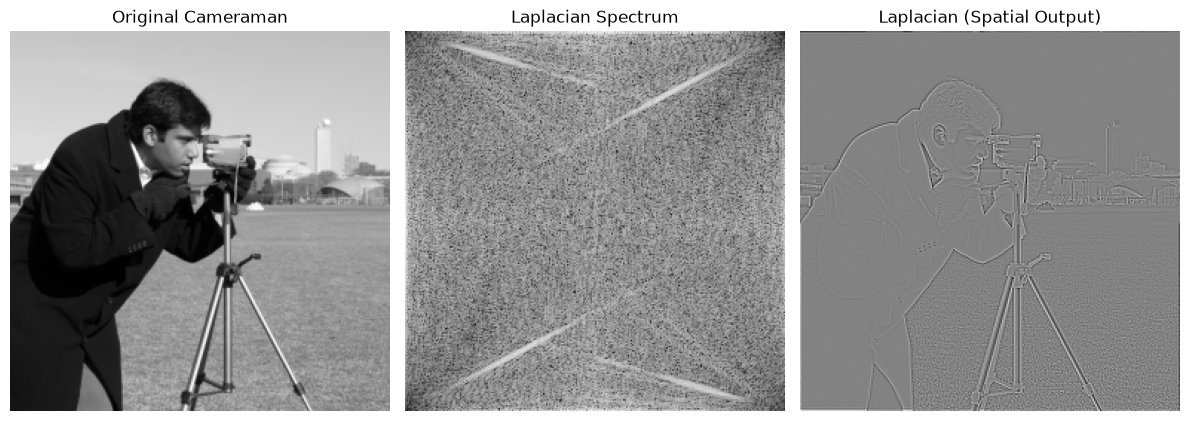

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.transform import resize
# Load cameraman image (already grayscale)
image = data.camera()
image = resize(image, (256, 256)) # Resize for faster FFT (optional)
# Get image size
M, N = image.shape
# Generate frequency grid (centered)
u = np.fft.fftfreq(M).reshape(-1, 1)
v = np.fft.fftfreq(N).reshape(1, -1)
# Compute Laplacian filter in frequency domain
laplacian_filter = -4 * (np.pi ** 2) * (u**2 + v**2)
# Apply 2D FFT
F = np.fft.fft2(image)
# Apply Laplacian filter in frequency domain
F_lap = F * laplacian_filter
# Inverse FFT to get spatial result
laplacian_image = np.fft.ifft2(F_lap).real
# Plot results
plt.figure(figsize=(12, 5))
plt.subplot(1, 3, 1)
plt.imshow(image, cmap='gray')
plt.title('Original Cameraman')
plt.axis('off')
plt.subplot(1, 3, 2)
plt.imshow(np.log(1 + np.abs(F_lap)), cmap='gray')
plt.title('Laplacian Spectrum')
plt.axis('off')
plt.subplot(1, 3, 3)
plt.imshow(laplacian_image, cmap='gray')
plt.title('Laplacian (Spatial Output)')
plt.axis('off')
plt.tight_layout()
plt.show()

Assessment Tasks:

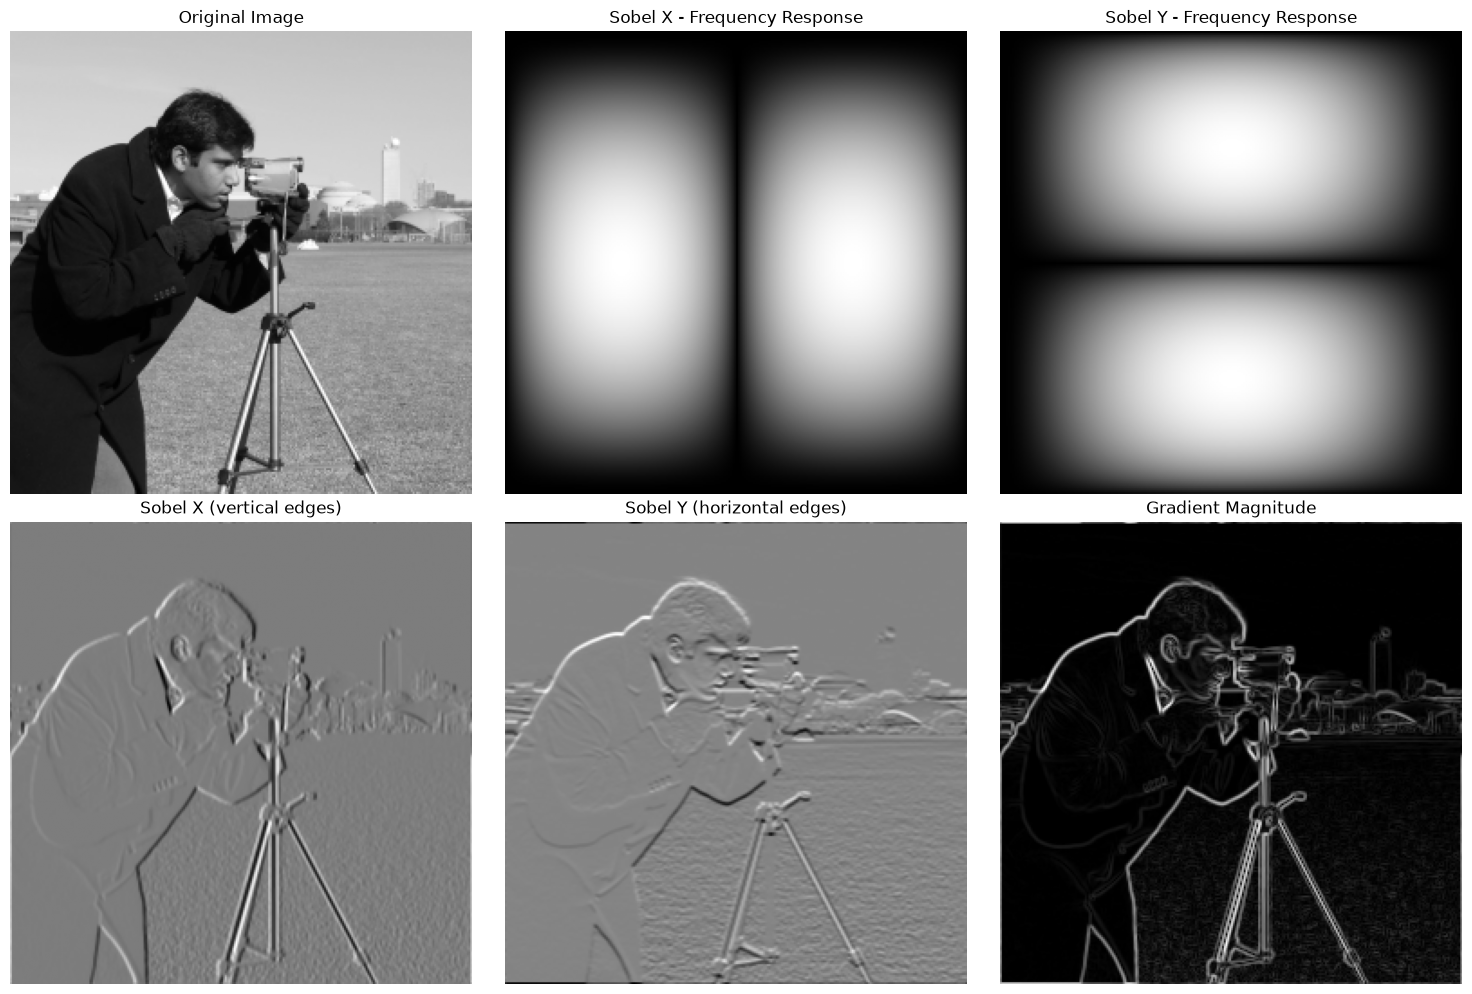

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from numpy.fft import fft2, ifft2, ifftshift

# Load and resize image (grayscale, float in [0, 1])
image = data.camera()
image = cv2.resize(image, (256, 256))
image_float = image.astype(np.float32) / 255.0

# Sobel filters
sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]])

sobel_y = np.array([[-1, -2, -1],
                    [ 0,  0,  0],
                    [ 1,  2,  1]])

# Proper padding and centering of kernel in spatial domain
def center_embed_kernel(kernel, shape):
    padded = np.zeros(shape)
    kh, kw = kernel.shape
    ph, pw = shape
    # Find center coordinates
    cy, cx = ph // 2, pw // 2
    # Insert kernel centered at the image center
    padded[cy - kh//2:cy - kh//2 + kh, cx - kw//2:cx - kw//2 + kw] = kernel
    return fft2(ifftshift(padded))  # Shift before FFT to place (0,0) at top-left

# Compute FFT of image
F_image = fft2(image_float)

# FFT of centered Sobel filters (use the provided function)
F_sobel_x = center_embed_kernel(sobel_x, image_float.shape)
F_sobel_y = center_embed_kernel(sobel_y, image_float.shape)

# Multiply in the frequency domain
# (multiplication in frequency = convolution in space)
F_gx = F_image * F_sobel_x
F_gy = F_image * F_sobel_y

# Back to the spatial domain
gx = np.real(ifft2(F_gx))
gy = np.real(ifft2(F_gy))
magnitude = np.sqrt(gx**2 + gy**2)

# Magnitude spectra (log scale) of the filters, for visualization
spec_x = np.log1p(np.abs(np.fft.fftshift(F_sobel_x)))
spec_y = np.log1p(np.abs(np.fft.fftshift(F_sobel_y)))

# Plot
fig, ax = plt.subplots(2, 3, figsize=(15, 10))

ax[0, 0].imshow(image_float, cmap='gray')
ax[0, 0].set_title("Original Image")

ax[0, 1].imshow(spec_x, cmap='gray')
ax[0, 1].set_title("Sobel X - Frequency Response")

ax[0, 2].imshow(spec_y, cmap='gray')
ax[0, 2].set_title("Sobel Y - Frequency Response")

ax[1, 0].imshow(gx, cmap='gray')
ax[1, 0].set_title("Sobel X (vertical edges)")

ax[1, 1].imshow(gy, cmap='gray')
ax[1, 1].set_title("Sobel Y (horizontal edges)")

ax[1, 2].imshow(magnitude, cmap='gray')
ax[1, 2].set_title("Gradient Magnitude")

for a in ax.ravel():
    a.axis("off")

plt.tight_layout()
plt.show()